In [9]:

print("Welcome to my AI/ML Internship")
print("Project 1: Iris Flower Classification")
print("Let's start Machine Learning!")

Welcome to my AI/ML Internship
Project 1: Iris Flower Classification
Let's start Machine Learning!


In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris


In [11]:
iris = load_iris()

In [12]:
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

In [13]:
df["species"] = [
    iris.target_names[i] for i in iris.target
]


In [14]:
print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  


In [15]:
print("Dataset size:", df.shape)
print("Flower species:", df["species"].unique())
print("Missing values:")
print(df.isnull().sum())


Dataset size: (150, 5)
Flower species: [np.str_('setosa') np.str_('versicolor') np.str_('virginica')]
Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64


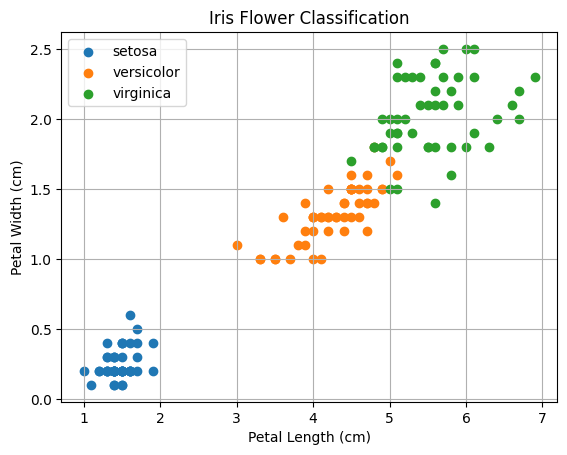

In [16]:
import matplotlib.pyplot as plt

for species in df["species"].unique():
    subset = df[df["species"] == species]

    plt.scatter(
        subset["petal length (cm)"],
        subset["petal width (cm)"],
        label=species
    )

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Iris Flower Classification")
plt.legend()
plt.grid(True)
plt.show()

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
# Prepare input data and target labels
X = iris.data
y = iris.target

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create the machine learning model
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=200)
)

# Train the model
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [18]:
# Predict flower species
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")


Model Accuracy: 93.33 %


In [19]:
flower = [[5.1, 3.5, 1.4, 0.2]]

prediction = model.predict(flower)

print("Predicted species:", iris.target_names[prediction[0]])

Predicted species: setosa


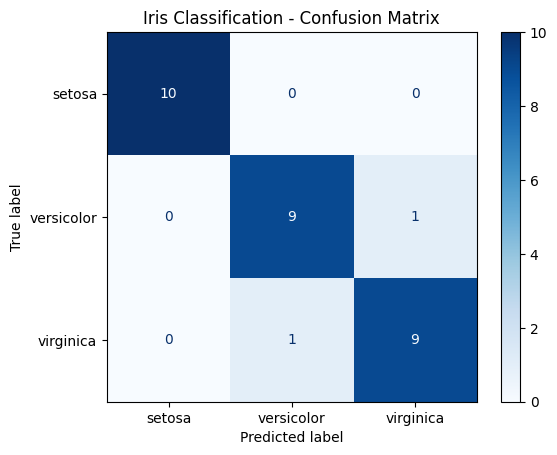

In [20]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=iris.target_names,
    cmap="Blues"
)

plt.title("Iris Classification - Confusion Matrix")
plt.show()

In [21]:

from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

